### 26/27 Season

In [9]:
# -------------------------------------------
# 1. Load the event data for the top 5 Leagues
# for 25/26 and 26/27 seasons
# -------------------------------------------
from pathlib import Path
import pandas as pd
import numpy as np

# Define leagues
leagues_26 = ["premier_league",
           "la_liga",
           "serie_a",
           "bundesliga",
           "ligue_1"]

# Initiate df list
leagues_df_26 = []

# Loop through leagues, adding events to the list
for league in leagues_26:

    league_events = pd.read_csv(Path.cwd().parent /f"data/raw/{league}_2026_2027_event_data.csv")

    leagues_df_26.append(league_events)

# Concat events into one df
event_data_26 = pd.concat(leagues_df_26, ignore_index = True)

# Preserve original event order
event_data_26["_original_order"] = np.arange(len(event_data_26))

# Define leagues
leagues_25 = ["prem",
           "la-liga",
           "serie-a",
           "bundesliga",
           "ligue1"]

# Initiate df list
leagues_df_25 = []

# Loop through leagues, adding events to the list
for league in leagues_25:

    league_events = pd.read_csv(Path.cwd().parent /f"data/raw/{league}-event-data-25-26.csv")
    

    if league == "bundesliga":
        league_events["season"] = 2526
        league_events["league"] = "GER-Bundesliga"
    elif league == "prem":
        league_events["season"] = 2526
        league_events["league"] = "ENG-Premier League"

    leagues_df_25.append(league_events)

# Concat events into one df
event_data_25 = pd.concat(leagues_df_25, ignore_index = True)

# Preserve original event order
event_data_25["_original_order"] = np.arange(len(event_data_25))

In [11]:
# -------------------------------------------
# 2. Combine the event data
# -------------------------------------------
# Combine both seasons
event_data = pd.concat(
    [event_data_25, event_data_26],
    ignore_index=True)

print(len(event_data))
print(event_data.groupby(["season", "league"]).size())

3446193
season  league            
2526    ENG-Premier League    577884
        ESP-La Liga           577205
        FRA-Ligue 1           467318
        GER-Bundesliga        478270
        ITA-Serie A           562672
2627    ENG-Premier League    154183
        ESP-La Liga           184330
        FRA-Ligue 1           143356
        GER-Bundesliga        130085
        ITA-Serie A           170890
dtype: int64


In [13]:
# -------------------------------------------
# 3. Define a function to create features, predict 
# xPass and aggregate per player per match and season
# -------------------------------------------

import sys

# Define project folder
project_folder = Path.cwd().parent

# Allow imports from src
sys.path.append(str(project_folder))

# Import features script
from src.xpass.features import create_xpass_features
from src.xpass.predictions import predict_xpass

# Define a function to compile the data
def compile_data(df):

    # Create features
    passes_df = create_xpass_features(df)

    # Predict xPass
    xpass_df = predict_xpass(passes_df = passes_df,
                             model_path = project_folder / "model/xpass_gb_model.pkl",
                             features_path = project_folder /"model/xpass_features.pkl")

    # Aggregate per match
    player_match_xpass = (xpass_df.groupby(["game_id", "player_id", "player",
                                            "season", "league"]).agg(total_xPass=('xPass', 'sum'),
                                                                     avg_xPass=('xPass', 'mean'),
                                                                     attempted_passes = ("outcome", "count"),
                                                                     completed_passes = ("outcome", lambda x: (x == 1).sum()),
                                                                     incompleted_passes = ("outcome", lambda x: (x == 0).sum()),
                                                                     PAx=('PAx', 'sum')).reset_index())

    # Aggregate across the season
    player_season_xpass = (player_match_xpass.groupby(["player_id", "player",
                                                       "season","league"]).agg(total_xPass = ("total_xPass", "sum"),
                                                                               attempted_passes = ("attempted_passes", "sum"),
                                                                               completed_passes = ("completed_passes", "sum"),
                                                                               incompleted_passes = ("incompleted_passes", "sum"),
                                                                               PAx = ("PAx", "sum"),
                                                                               matches_played = ("game_id", "count")).reset_index())

    # Create extra season level metrics
    player_season_xpass['avg_xPass'] = (player_season_xpass['total_xPass'] / player_season_xpass['attempted_passes'])
    player_season_xpass["PAx_per_100"] = (player_season_xpass["PAx"] / player_season_xpass["attempted_passes"]) * 100
    player_season_xpass["passing_acc"] = (player_season_xpass["completed_passes"] / player_season_xpass["attempted_passes"]) * 100


    return xpass_df, player_match_xpass, player_season_xpass

xpass_df, player_match_xpass, player_season_xpass = compile_data(event_data)

In [17]:
# -------------------------------------------
# 4. Calculate player changes between 2025 and 26
# -------------------------------------------
player_25 = (
    player_season_xpass[
        player_season_xpass["season"] == 2526
    ]
    .groupby("player_id", as_index=False)
    .agg(
        player=("player", "last"),
        total_xPass=("total_xPass", "sum"),
        attempted_passes=("attempted_passes", "sum"),
        completed_passes=("completed_passes", "sum"),
        incompleted_passes=("incompleted_passes", "sum"),
        PAx=("PAx", "sum"),
        matches_played=("matches_played", "sum")
    )
)

# Recalculate metrics from combined totals
player_25["avg_xPass"] = (
    player_25["total_xPass"] / player_25["attempted_passes"]
)

player_25["PAx_per_100"] = (
    player_25["PAx"] / player_25["attempted_passes"] * 100
)

player_25["passing_acc"] = (
    player_25["completed_passes"] / player_25["attempted_passes"] * 100
)

player_26_league = (
    player_season_xpass[
        player_season_xpass["season"] == 2627
    ]
    .sort_values("matches_played", ascending=False)
    .drop_duplicates("player_id")
    [["player_id", "league"]]
)
player_26 = player_season_xpass[
    player_season_xpass["season"] == 2627
].copy()

player_26_totals = (
    player_26.groupby("player_id", as_index=False)
    .agg(
        player=("player", "last"),
        total_xPass=("total_xPass", "sum"),
        attempted_passes=("attempted_passes", "sum"),
        completed_passes=("completed_passes", "sum"),
        incompleted_passes=("incompleted_passes", "sum"),
        PAx=("PAx", "sum"),
        matches_played=("matches_played", "sum")
    )
)

player_26 = player_26_totals.merge(
    player_26_league,
    on="player_id"
)

player_26["avg_xPass"] = (
    player_26["total_xPass"] / player_26["attempted_passes"]
)

player_26["PAx_per_100"] = (
    player_26["PAx"] / player_26["attempted_passes"] * 100
)

player_26["passing_acc"] = (
    player_26["completed_passes"] / player_26["attempted_passes"] * 100
)

trajectory_df = player_25.merge(
    player_26,
    on="player_id",
    how="inner",
    suffixes=("_25", "_26")
)

trajectory_filtered = trajectory_df[
    (trajectory_df["attempted_passes_25"] >= 400) &
    (trajectory_df["attempted_passes_26"] >= 100)
].copy()

trajectory_filtered = trajectory_filtered.copy()

trajectory_filtered["player"] = trajectory_filtered["player_26"]

trajectory_filtered["change_avg_xPass"] = (
    trajectory_filtered["avg_xPass_26"] -
    trajectory_filtered["avg_xPass_25"]
)

trajectory_filtered["change_PAx"] = (
    trajectory_filtered["PAx_per_100_26"] -
    trajectory_filtered["PAx_per_100_25"]
)



Updated: /Users/Seth/Desktop/Football Analyses/xPass/figures/xpass_trajectory.html


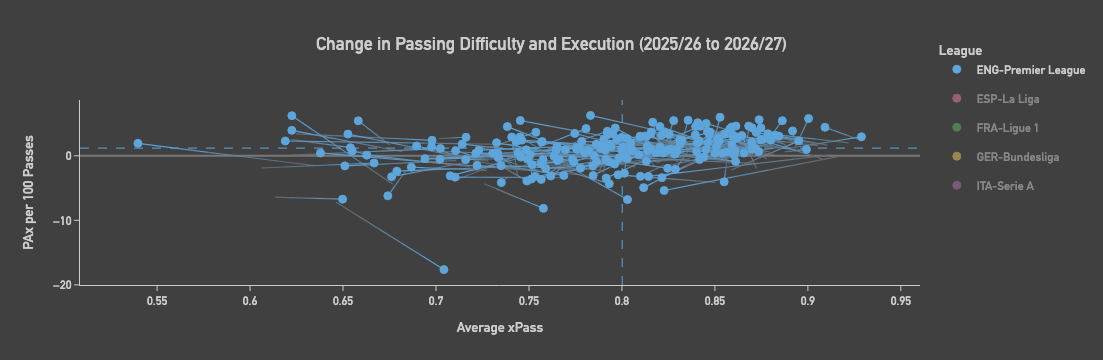

In [23]:

# -------------------------------------------
# 4. Plot the trajectory figure
# -------------------------------------------

import json
import numpy as np
import plotly.graph_objects as go

fig = go.Figure()

n_segments = 5
default_league = "ENG-Premier League"

league_colours = {
    "ENG-Premier League": "#5DA5DA",
    "ESP-La Liga": "#F17CB0",
    "FRA-Ligue 1": "#60BD68",
    "GER-Bundesliga": "#F2CF5B",
    "ITA-Serie A": "#B276B2"
}

league_medians = (
    trajectory_filtered
    .groupby("league")
    .agg(
        median_avg_xPass=("avg_xPass_26", "median"),
        median_PAx_per_100=("PAx_per_100_26", "median")
    )
)
# -------------------------------------------
# Calculate league-specific axis ranges
# -------------------------------------------

league_axis_ranges = {}

for league in league_colours:

    league_data = trajectory_filtered[
        trajectory_filtered["league"] == league
    ]

    x_values = np.concatenate([
        league_data["avg_xPass_25"].to_numpy(),
        league_data["avg_xPass_26"].to_numpy()
    ])

    y_values = np.concatenate([
        league_data["PAx_per_100_25"].to_numpy(),
        league_data["PAx_per_100_26"].to_numpy()
    ])

    x_min, x_max = np.nanmin(x_values), np.nanmax(x_values)
    y_min, y_max = np.nanmin(y_values), np.nanmax(y_values)

    x_padding = (x_max - x_min) * 0.08
    y_padding = (y_max - y_min) * 0.10

    league_axis_ranges[league] = {
        "x": [x_min - x_padding, x_max + x_padding],
        "y": [y_min - y_padding, y_max + y_padding]
    }

league_axis_ranges_json = json.dumps(league_axis_ranges)

# -------------------------------------------
# Build league traces
# -------------------------------------------

for league, colour in league_colours.items():

    league_data = trajectory_filtered[
        trajectory_filtered["league"] == league
    ]

    visible = True if league == default_league else "legendonly"

    rgb = np.array([
        int(colour[i:i+2], 16)
        for i in (1, 3, 5)
    ])

    start_colour = np.array([100, 100, 100])

    # Gradient trajectory segments
    for i in range(n_segments):

        x_values = []
        y_values = []

        t1 = i / n_segments
        t2 = (i + 1) / n_segments

        for _, player in league_data.iterrows():

            x_start = player["avg_xPass_25"]
            y_start = player["PAx_per_100_25"]

            x_end = player["avg_xPass_26"]
            y_end = player["PAx_per_100_26"]

            x1 = x_start + (x_end - x_start) * t1
            y1 = y_start + (y_end - y_start) * t1

            x2 = x_start + (x_end - x_start) * t2
            y2 = y_start + (y_end - y_start) * t2

            x_values.extend([x1, x2, None])
            y_values.extend([y1, y2, None])

        blend = (t1 + t2) / 2

        segment_colour = (
            start_colour * (1 - blend) +
            rgb * blend
        ).astype(int)

        segment_hex = "#{:02x}{:02x}{:02x}".format(
            *segment_colour
        )

        fig.add_trace(
            go.Scatter(
                x=x_values,
                y=y_values,
                mode="lines",
                line=dict(color=segment_hex, width=1.2),
                legendgroup=league,
                showlegend=False,
                visible=visible,
                hoverinfo="skip"
            )
        )

    # Marker customdata: exactly seven columns
    customdata = league_data[
        [
            "player",
            "avg_xPass_25",
            "avg_xPass_26",
            "PAx_per_100_25",
            "PAx_per_100_26",
            "avg_xPass_25",
            "PAx_per_100_25"
        ]
    ].to_numpy(dtype=object)

    # Player markers
    fig.add_trace(
        go.Scatter(
            x=league_data["avg_xPass_26"],
            y=league_data["PAx_per_100_26"],
            mode="markers",
            name=league,
            legendgroup=league,
            showlegend=True,
            visible=visible,
            marker=dict(
                size=8,
                color=colour,
                line=dict(color=colour, width=1)
            ),
            customdata=customdata,
            hoverinfo="none"
        )
    )

    # Median boundaries
    x_median = league_medians.loc[
        league, "median_avg_xPass"
    ]

    y_median = league_medians.loc[
        league, "median_PAx_per_100"
    ]

    fig.add_trace(
        go.Scatter(
            x=[x_median, x_median],
            y=league_axis_ranges[league]["y"],
            mode="lines",
            line=dict(color=colour, width=1, dash="dash"),
            legendgroup=league,
            showlegend=False,
            visible=visible,
            hoverinfo="skip"
        )
    )

    fig.add_trace(
        go.Scatter(
            x=league_axis_ranges[league]["x"],
            y=[y_median, y_median],
            mode="lines",
            line=dict(color=colour, width=1, dash="dash"),
            legendgroup=league,
            showlegend=False,
            visible=visible,
            hoverinfo="skip"
        )
    )


# -------------------------------------------
# Chart styling
# -------------------------------------------

fig.update_layout(
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",

    font=dict(
        family="DIN Alternate",
        color="#CCCCCC",
        size=12
    ),

    width=None,
    height=None,
    autosize=True,

    title=dict(
        text="Change in Passing Difficulty and Execution (2025/26 to 2026/27)",
        x=0.5,
        xanchor="center",
        font=dict(size=18)
    ),

    xaxis=dict(
        title="Average xPass",
        range=league_axis_ranges[default_league]["x"],
        showgrid=False,
        zeroline=False,
        showline=True,
        linecolor="#CCCCCC",
        ticks="outside",
        tickcolor="#CCCCCC"
    ),

    yaxis=dict(
        title="PAx per 100 Passes",
        range=league_axis_ranges[default_league]["y"],
        showgrid=False,
        zeroline=True,
        zerolinecolor="#777777",
        showline=True,
        linecolor="#CCCCCC",
        ticks="outside",
        tickcolor="#CCCCCC"
    ),

    legend=dict(
        title="League",
        orientation="v",
        x=1.02,
        y=0.9,
        xanchor="left",
        yanchor="middle",
        bgcolor="rgba(0,0,0,0)",
        groupclick="togglegroup",
        itemclick="toggleothers"
    ),

    hoverlabel=dict(
        bgcolor="#292929",
        bordercolor="#CCCCCC",
        font=dict(
            family="DIN Alternate",
            color="#FFFFFF",
            size=12
        )
    ),

    margin=dict(
        l=80,
        r=180,
        t=100,
        b=75
    )
)


# -------------------------------------------
# Export base figure
# -------------------------------------------

html = fig.to_html(
    full_html=True,
    include_plotlyjs=True,
    div_id="xpass-chart"
)

trace_groups = {}

for i, league in enumerate(league_colours):

    base = i * 8

    trace_groups[league] = {
        "lines": list(range(base, base + 5)),
        "marker": base + 5
    }

trace_groups_json = json.dumps(trace_groups)
colours_json = json.dumps(league_colours)


# -------------------------------------------
# Interactive JavaScript
# -------------------------------------------

highlight_script = f"""
<script>
(function() {{

    const gd = document.getElementById("xpass-chart");

    const groups = {trace_groups_json};
    const colours = {colours_json};
    const axisRanges = {league_axis_ranges_json};

    const nSegments = 5;
    const baseTraceCount = gd.data.length;

    const overlayLineIndices = Array.from(
        {{length: nSegments}},
        (_, i) => baseTraceCount + i
    );

    const overlayMarkerIndex = baseTraceCount + nSegments;

    const overlays = [];

    for (let i = 0; i < nSegments; i++) {{
        overlays.push({{
            x: [],
            y: [],
            mode: "lines",
            line: {{color: "#FFFFFF", width: 3}},
            hoverinfo: "skip",
            showlegend: false
        }});
    }}

    overlays.push({{
        x: [],
        y: [],
        mode: "markers",
        marker: {{size: 13, color: "#FFFFFF"}},
        hoverinfo: "skip",
        showlegend: false
    }});

    Plotly.addTraces(gd, overlays).then(function() {{

        let activeLeague = null;

        const panel = document.createElement("div");

        panel.style.position = "absolute";
        panel.style.top = "75px";
        panel.style.left = "100px";
        panel.style.zIndex = "1000";
        panel.style.background = "rgba(35,35,35,0.95)";
        panel.style.border = "1px solid #777777";
        panel.style.borderRadius = "5px";
        panel.style.padding = "12px 16px";
        panel.style.color = "#CCCCCC";
        panel.style.fontFamily = "DIN Alternate, sans-serif";
        panel.style.fontSize = "13px";
        panel.style.lineHeight = "1.7";
        panel.style.minWidth = "210px";
        panel.style.display = "none";
        panel.style.pointerEvents = "none";

        gd.style.position = "relative";
        gd.appendChild(panel);


        // Clear overlay traces
        function clearOverlays() {{

            overlayLineIndices.forEach(function(index) {{
                Plotly.restyle(
                    gd,
                    {{x: [[]], y: [[]]}},
                    [index]
                );
            }});

            Plotly.restyle(
                gd,
                {{x: [[]], y: [[]]}},
                [overlayMarkerIndex]
            );
        }}


        // Reset active player
        function resetHighlight() {{

            if (activeLeague === null) return;

            const group = groups[activeLeague];

            Plotly.restyle(
                gd,
                {{opacity: 1}},
                [...group.lines, group.marker]
            );

            clearOverlays();

            panel.style.display = "none";
            activeLeague = null;
        }}


        // Draw player trajectory
        function highlightPoint(point) {{

            if (activeLeague !== null) {{
                resetHighlight();
            }}

            const league = point.data.legendgroup;
            const group = groups[league];

            activeLeague = league;

            Plotly.restyle(
                gd,
                {{opacity: 0.12}},
                [...group.lines, group.marker]
            );

            const custom = point.customdata;

            const x0 = Number(custom[5]);
            const y0 = Number(custom[6]);

            const x1 = Number(point.x);
            const y1 = Number(point.y);

            const hex = colours[league];

            const rgb = [
                parseInt(hex.slice(1, 3), 16),
                parseInt(hex.slice(3, 5), 16),
                parseInt(hex.slice(5, 7), 16)
            ];

            const start = [100, 100, 100];

            for (let i = 0; i < nSegments; i++) {{

                const t1 = i / nSegments;
                const t2 = (i + 1) / nSegments;
                const blend = (t1 + t2) / 2;

                const segmentColour = start.map(
                    (value, j) =>
                        Math.round(
                            value * (1 - blend) + rgb[j] * blend
                        )
                );

                const segmentHex = "#" +
                    segmentColour.map(
                        value => value.toString(16).padStart(2, "0")
                    ).join("");

                const sx = x0 + (x1 - x0) * t1;
                const sy = y0 + (y1 - y0) * t1;

                const ex = x0 + (x1 - x0) * t2;
                const ey = y0 + (y1 - y0) * t2;

                Plotly.restyle(
                    gd,
                    {{
                        x: [[sx, ex]],
                        y: [[sy, ey]],
                        line: [{{color: segmentHex, width: 3}}],
                        opacity: [1]
                    }},
                    [overlayLineIndices[i]]
                );
            }}

            Plotly.restyle(
                gd,
                {{
                    x: [[x1]],
                    y: [[y1]],
                    marker: [{{
                        size: 13,
                        color: hex,
                        line: {{color: "#FFFFFF", width: 1.5}}
                    }}],
                    opacity: [1]
                }},
                [overlayMarkerIndex]
            );

            panel.innerHTML = `
                <div style="font-size:16px; font-weight:bold;
                            color:${{hex}}; margin-bottom:8px;">
                    ${{custom[0]}}
                </div>
                <div style="font-weight:bold;">Average xPass</div>
                2025/26: ${{Number(custom[1]).toFixed(3)}}<br>
                2026/27: ${{Number(custom[2]).toFixed(3)}}
                <div style="font-weight:bold; margin-top:8px;">
                    PAx per 100 passes
                </div>
                2025/26: ${{Number(custom[3]).toFixed(2)}}<br>
                2026/27: ${{Number(custom[4]).toFixed(2)}}
            `;

            panel.style.display = "block";
        }}


        // Find the marker trace from a Plotly event
        function getMarkerPoint(event) {{

            return event.points.find(p => {{
                const league = p.data.legendgroup;

                return groups[league] &&
                       p.curveNumber === groups[league].marker;
            }});
        }}


        // Hover highlighting
        gd.on("plotly_hover", function(event) {{

            const point = getMarkerPoint(event);

            if (!point) return;

            highlightPoint(point);
        }});


        gd.on("plotly_unhover", function() {{
            resetHighlight();
        }});


        // League switching and axis rescaling
        gd.on("plotly_legendclick", function(event) {{

            const clickedTrace = gd.data[event.curveNumber];
            const league = clickedTrace.legendgroup;

            if (!axisRanges[league]) return false;

            resetHighlight();

            const indices = Array.from(
                {{length: baseTraceCount}},
                (_, i) => i
            );

            const visibility = gd.data
                .slice(0, baseTraceCount)
                .map(trace =>
                    trace.legendgroup === league ? true : "legendonly"
                );

            Plotly.restyle(
                gd,
                {{visible: visibility}},
                indices
            ).then(function() {{

                Plotly.relayout(gd, {{
                    "xaxis.range": axisRanges[league].x,
                    "yaxis.range": axisRanges[league].y
                }});

            }});

            return false;
        }});

    }});

}})();
</script>
"""


# -------------------------------------------
# Save final HTML
# -------------------------------------------

html = html.replace("</body>", highlight_script + "\\n</body>")

from pathlib import Path

html_path = Path.cwd().parent / "figures/xpass_trajectory.html"
html_path.write_text(html, encoding="utf-8")

print("Updated:", html_path.resolve())

fig.show()



Dani Olmo vs Racing Santander
----------------------------------------
Passes attempted: 69
Passes completed: 63
Passing accuracy: 91.3%
Expected completions: 55.04
Total PAx: +7.96
Average xPass: 0.80


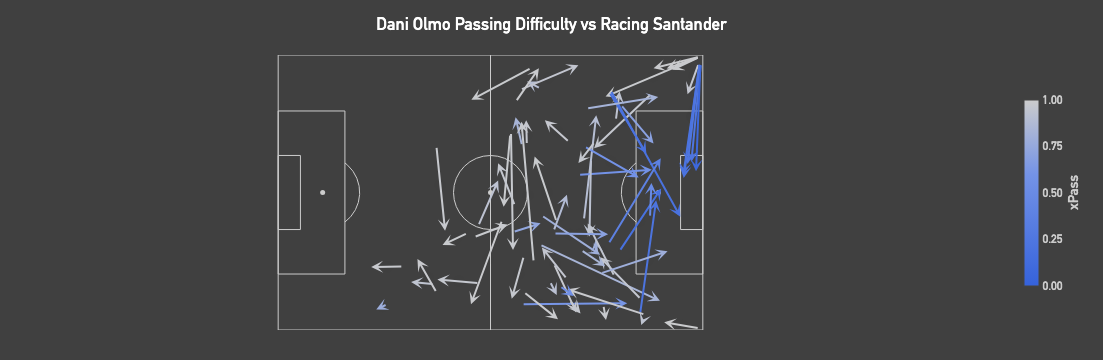

In [33]:
import importlib
import src.xpass.plotting as plotting

importlib.reload(plotting)

fig, player_passes = plotting.plot_xpass_map(
    df=xpass_df,
    match_id=1994181,
    player_name="Dani Olmo",
    opposition="Racing Santander"
)

fig.show()

In [319]:
display(player_match_xpass[player_match_xpass["player"] == "Trey Nyoni"])

,game_id,player_id,player,season,league,total_xPass,avg_xPass,attempted_passes,completed_passes,incompleted_passes,PAx
17190,1903296,509423.0,Trey Nyoni,2526,ENG-Premier League,0.104460,0.104460,1,1,0,0.895540
17771,1903316,509423.0,Trey Nyoni,2526,ENG-Premier League,0.882208,0.882208,1,1,0,0.117792
19032,1903359,509423.0,Trey Nyoni,2526,ENG-Premier League,7.958057,0.795806,10,9,1,1.041943
20482,1903408,509423.0,Trey Nyoni,2526,ENG-Premier League,1.713115,0.856558,2,1,1,-0.713115
21634,1903447,509423.0,Trey Nyoni,2526,ENG-Premier League,6.263191,0.894742,7,7,0,0.736809
22481,1903475,509423.0,Trey Nyoni,2526,ENG-Premier League,0.964105,0.964105,1,1,0,0.035895
57420,1983560,509423.0,Trey Nyoni,2627,ENG-Premier League,17.414155,0.870708,20,18,2,0.585845
57751,1983571,509423.0,Trey Nyoni,2627,ENG-Premier League,9.050447,0.822768,11,9,2,-0.050447
58026,1983580,509423.0,Trey Nyoni,2627,ENG-Premier League,4.318089,0.863618,5,5,0,0.681911
58733,1983603,509423.0,Trey Nyoni,2627,ENG-Premier League,3.697362,0.739472,5,4,1,0.302638


In [47]:
display(trajectory_filtered[trajectory_filtered["player"] == "Moisés Caicedo"])

,player_id,player_25,total_xPass_25,attempted_passes_25,completed_passes_25,incompleted_passes_25,PAx_25,matches_played_25,avg_xPass_25,PAx_per_100_25,...,incompleted_passes_26,PAx_26,matches_played_26,league,avg_xPass_26,PAx_per_100_26,passing_acc_26,player,change_avg_xPass,change_PAx
1009,410175.0,Moisés Caicedo,1856.388355,2066,1891,175,34.611645,33,0.898542,1.675297,...,26,13.011686,6,ENG-Premier League,0.869961,4.337229,91.333333,Moisés Caicedo,-0.028581,2.661931


In [77]:

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.reset_option("display.width")
display(
    trajectory_filtered[
        (trajectory_filtered["league"] == "ENG-Premier League") &
        (trajectory_filtered["change_avg_xPass"] > 0) &
        (trajectory_filtered["change_PAx"] > 0)
    ]
)

,player_id,player_25,total_xPass_25,attempted_passes_25,completed_passes_25,incompleted_passes_25,PAx_25,matches_played_25,avg_xPass_25,PAx_per_100_25,passing_acc_25,player_26,total_xPass_26,attempted_passes_26,completed_passes_26,incompleted_passes_26,PAx_26,matches_played_26,league,avg_xPass_26,PAx_per_100_26,passing_acc_26,player,change_avg_xPass,change_PAx
22,68659.0,Jordan Henderson,943.718180,1209,921,288,-22.718180,32,0.780577,-1.879089,76.178660,Jordan Henderson,262.209168,331,273,58,10.790832,5,ENG-Premier League,0.792173,3.260070,82.477341,Jordan Henderson,0.011595,5.139159
49,82277.0,Dan Burn,916.875277,1165,903,262,-13.875277,29,0.787017,-1.191011,77.510730,Dan Burn,117.912623,149,117,32,-0.912623,5,ENG-Premier League,0.791360,-0.612499,78.523490,Dan Burn,0.004342,0.578512
126,115726.0,Andy Robertson,665.612215,841,671,170,5.387785,23,0.791453,0.640640,79.785969,Andy Robertson,457.850091,572,466,106,8.149909,9,ENG-Premier League,0.800437,1.424809,81.468531,Andy Robertson,0.008984,0.784169
153,128882.0,Ryan Christie,447.203711,566,433,133,-14.203711,26,0.790113,-2.509490,76.501767,Ryan Christie,164.235637,207,168,39,3.764363,9,ENG-Premier League,0.793409,1.818533,81.159420,Ryan Christie,0.003296,4.328023
162,131464.0,James Tarkowski,1257.555762,1568,1260,308,2.444238,37,0.802013,0.155882,80.357143,James Tarkowski,395.758196,480,400,80,4.241804,10,ENG-Premier League,0.824496,0.883709,83.333333,James Tarkowski,0.022484,0.727827
166,133464.0,Jefferson Lerma,726.624152,945,724,221,-2.624152,31,0.768914,-0.277688,76.613757,Jefferson Lerma,105.301483,135,106,29,0.698517,6,ENG-Premier League,0.780011,0.517420,78.518519,Jefferson Lerma,0.011097,0.795108
179,136345.0,Youri Tielemans,975.843295,1178,976,202,0.156705,25,0.828390,0.013303,82.852292,Youri Tielemans,413.397971,488,429,59,15.602029,9,ENG-Premier League,0.847127,3.197137,87.909836,Youri Tielemans,0.018737,3.183834
221,231135.0,Joachim Andersen,1975.576456,2310,1982,328,6.423544,33,0.855228,0.278075,85.800866,Joachim Andersen,174.878461,201,178,23,3.121539,3,ENG-Premier League,0.870042,1.553004,88.557214,Joachim Andersen,0.014814,1.274929
324,297395.0,Sasa Lukic,657.905207,799,645,154,-12.905207,26,0.823411,-1.615170,80.725907,Sasa Lukic,281.528456,327,284,43,2.471544,6,ENG-Premier League,0.860943,0.755824,86.850153,Sasa Lukic,0.037533,2.370994
343,300359.0,Issa Diop,426.555873,495,433,62,6.444127,13,0.861729,1.301844,87.474747,Issa Diop,494.075745,560,512,48,17.924255,10,ENG-Premier League,0.882278,3.200760,91.428571,Issa Diop,0.020549,1.898916


In [101]:
this_week_matches = [
    1983842,
    1983848,
    1983844,
    1983836,
    1983851,
    1983853,
    1983838,
    1983840,
    1983846,
    1983850]

this_week_players = player_match_xpass[
    player_match_xpass["game_id"].isin(this_week_matches)
]

display(
    this_week_players.nlargest(20, "PAx")
)

,game_id,player_id,player,season,league,total_xPass,avg_xPass,attempted_passes,completed_passes,incompleted_passes,PAx
60162,1983853,425319.0,Roméo Lavia,2627,ENG-Premier League,80.169511,0.871408,92,86,6,5.830489
60158,1983853,410175.0,Moisés Caicedo,2627,ENG-Premier League,75.197130,0.844912,89,81,8,5.802870
59993,1983844,136824.0,Alex Iwobi,2627,ENG-Premier League,43.206417,0.771543,56,49,7,5.793583
60136,1983851,402596.0,Elliot Anderson,2627,ENG-Premier League,97.339191,0.846428,115,103,12,5.660809
60103,1983850,437299.0,Leny Yoro,2627,ENG-Premier League,45.369100,0.872483,52,51,1,5.630900
59986,1983842,534073.0,Stephen Mfuni,2627,ENG-Premier League,39.509876,0.806324,49,45,4,5.490124
60144,1983853,68659.0,Jordan Henderson,2627,ENG-Premier League,63.921686,0.841075,76,69,7,5.078314
59898,1983838,86441.0,Lewis Dunk,2627,ENG-Premier League,65.945909,0.867709,76,71,5,5.054091
60105,1983850,460260.0,Kobbie Mainoo,2627,ENG-Premier League,61.000463,0.835623,73,66,7,4.999537
59909,1983838,392647.0,Maxim De Cuyper,2627,ENG-Premier League,38.228090,0.764562,50,43,7,4.771910


In [103]:
xpass_df.to_csv(Path.cwd().parent / "data/cleaned/all_xpass_25-27.csv", index = False)